# Simulating Different Toehold Mediated Exchange (TMSE) mechanisms for a Simplified DNA Gate

**Installing and Initializing Modules**: See [README](https://github.com/usnistgov/TMSE_BioCRNpyler_Library/blob/main/README.md) documentation for additional details.

This notebook illustrate how to compile and simulate a simplified DNA gate implementing all TMSE mechanism: **`OneStep()`**, **`TwoStep()`**, and **`ThreeStep()`**, in TMSE-BioCRNpyler modules.

Specific Features:
* specifying strand exchange molecules from a dictionary directly using `TMSE()`
* generating a strand exchange reactions at different level of abstractions

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from pathlib import Path
from matplotlib.gridspec import GridSpec

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 4 hours
timepoints = np.linspace(0,4,5001)*3600

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

In [3]:
def plot_subplots(tmse_steps, time, dict_specs, ax, ax_num, plot_dict):
    # Determine data ranges for alignment
    for col in R.columns:
        if 'complex' in col:
             data = R[col]
             ax.plot(time, data/1000, label=plot_dict[col][1],
                     linewidth=2, color= plot_dict[col][0], linestyle=plot_dict[col][2],)
    
    for key in dict_specs.keys():
        data = R[key]
        ax.plot(time, data/1000, label=dict_specs[key][1], 
                color=dict_specs[key][0], linewidth=2, linestyle=dict_specs[key][2])
    
    # Annotate compartment plot
    ax.text(.86, 0.75, tmse_steps,
            fontsize=22, fontstyle='italic',
            fontweight='light', fontfamily='sans-serif',
            transform=ax.transAxes)
    ax.set_ylim(-0.01, 0.16) 
    ax.set_xlim(0, 4) 

    for tick in ax.get_xticklabels():
            tick.set_fontsize(22)
    for tick in ax.get_yticklabels():
        tick.set_fontsize(22)

    if ax_num <2:
        plt.setp(ax.get_xticklabels(), visible=False) 
        if ax_num==1:
            ax.set_ylabel('Concentrations (μmol/L)', color='black', fontsize=22)
    else:
        ax.set_xlabel('Time (h)', fontsize=22)

## Simplified DNA AND Gate simulation

![Simplified DNA AND Gate](../schematics/Figure_TMSEmechs.png)
(A) Substrates (left) and products (right) involved in the TMSE mechanism. (B) Schematic representation of different TMSE mechanisms available: (i) `OneStepTME()`, (ii) `TwoStepTMSE()`, and (iii) `ThreeStepTMSE()`.

In [4]:
# Define initial DNA and Reporter RNA
sim_inputs = {
    'DNA_1': ['Input',2], # Input DNA
    'DNA_5':['Gate',2,4], # Gate DNA
    'RNA_1':['Reporter',4]} # Reporter DNA
     
# Components
step_tmse = TMSE(sim_inputs)

# Parameters and initical conditions
parameters_AND = {"kx":5e4/1e9,
                  "krev":5e4/1e9,
                  "krep":5e4/1e9,
                  "kb":5e4/1e9,
                  "kb_rev":5e4/1e9,
                  "ku":5e4/1e9,
                  "ku_rev":5e4/1e9,
                  } 

initial_concentration_dict = {'dna_Input_2':100,
                              'dna_Gate_2_4':200,
                              'dna_Reporter_4':150}

# Dictionary of TMSE mechanism
tmse_conditions = {'One-Step':[OneStepTMSE()],
                   'Two-Step': [TwoStepTMSE()],
                   'Three-Step': [ThreeStepTMSE()]}

# Dictionary for plotting
list_species=  {'dna_Signal_4':['rebeccapurple', 'DNA signal 4', 'dashed'],}
plot_dict= {'complex_dna_Gate_2_4_dna_Input_2_':['navy', 'Complex 1', 'solid'],
            'complex_dna_GateOut_2_2_dna_Output_2_4_': ['grey', 'Complex 2', 'solid']}

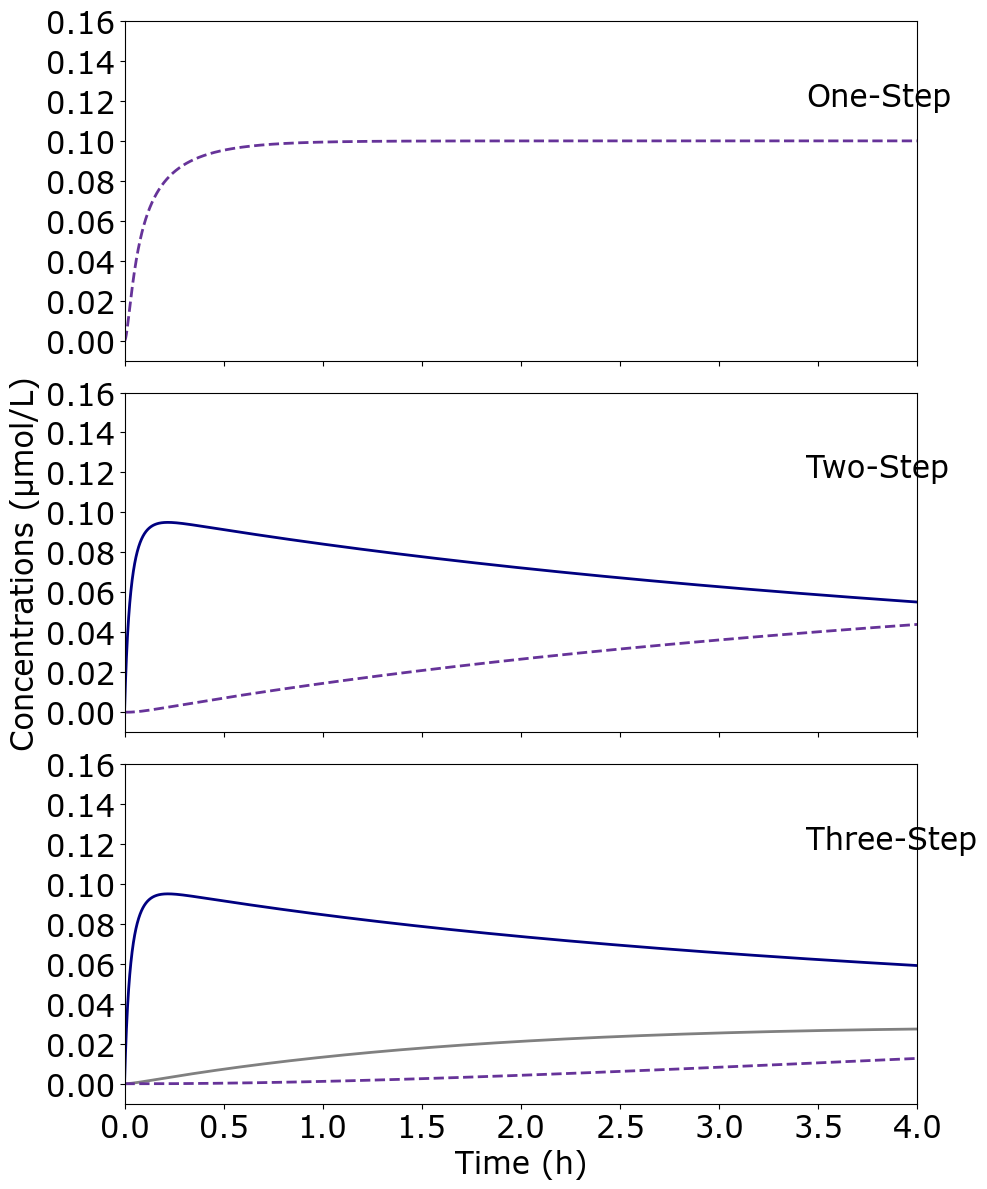

In [5]:
fig = plt.figure(figsize=(10, 12))  # Width set to match letter-size paper width (inches)
gs = GridSpec(3, 1, figure=fig, height_ratios=[1,1, 1])  # Equal heights for both subplots

for key, ax_num in zip(tmse_conditions.keys(), range(3)):
    mech_tmse = tmse_conditions[key][0]
    tmse_mechanisms = {mech_tmse.mechanism_type:mech_tmse}

    # Make Mixture and Compile
    M_DNAseesaw_AND = Mixture("SeeSaw_AND",
                              components=[step_tmse],
                              parameters=parameters_AND,
                              mechanisms=tmse_mechanisms)
    
    # Compile the CRN with Mixture.compile_crn
    CRN_DNAseesaw_AND = M_DNAseesaw_AND.compile_crn()

    # Simulate
    try:
        R = CRN_DNAseesaw_AND.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                               initial_condition_dict = initial_concentration_dict)
        time = R['time'] / 3600        
        ax=fig.add_subplot(gs[ax_num])

        #Plot
        plot_subplots(key, time, list_species, ax, ax_num, plot_dict)   

    except ModuleNotFoundError:
        print("Plotting Modules not installed.")

plt.savefig(f'{figs_dir}/SI_TMSEmechs.svg')
plt.tight_layout()

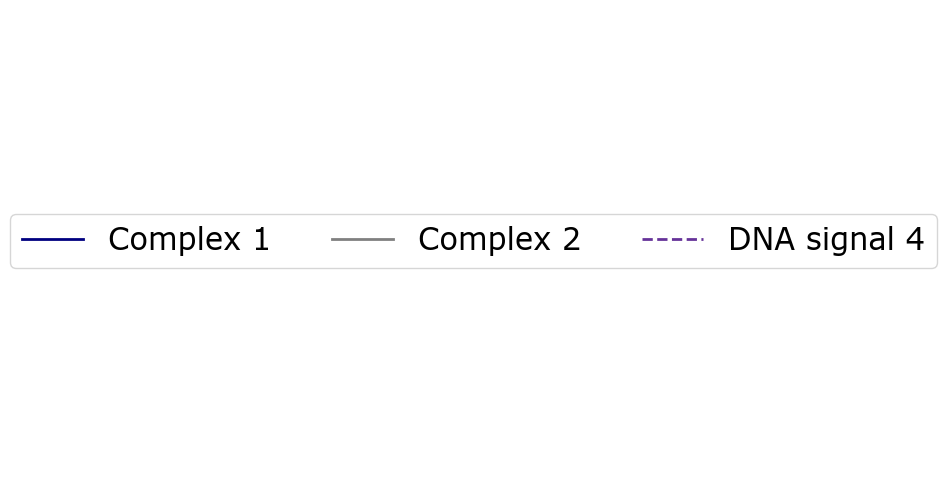

<Figure size 600x600 with 0 Axes>

In [6]:
handles, labels = [], []

def collect_handles_labels(ax):
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

collect_handles_labels(ax)

# Create a single-line legend with combined handles and labels
fig_legend, ax_legend = plt.subplots()
ax_legend.axis('off')
ax_legend.legend(handles, labels, loc='center', ncol=len(labels), bbox_to_anchor=(0.5, 0.5), fontsize=22)
plt.show()
plt.savefig(f'{figs_dir}/SI_TMSEmechs_legend.svg')

## Irreversible kinetic (i.e. k_rev = 0)

In [7]:
# Parameters and initical conditions
parameters_AND = {"kx":5e4/1e9,
                  "krev":0,
                  "krep":5e4/1e9,
                  "kb":5e4/1e9,
                  "kb_rev":0,
                  "ku":5e4/1e9,
                  "ku_rev":0,
                  } 

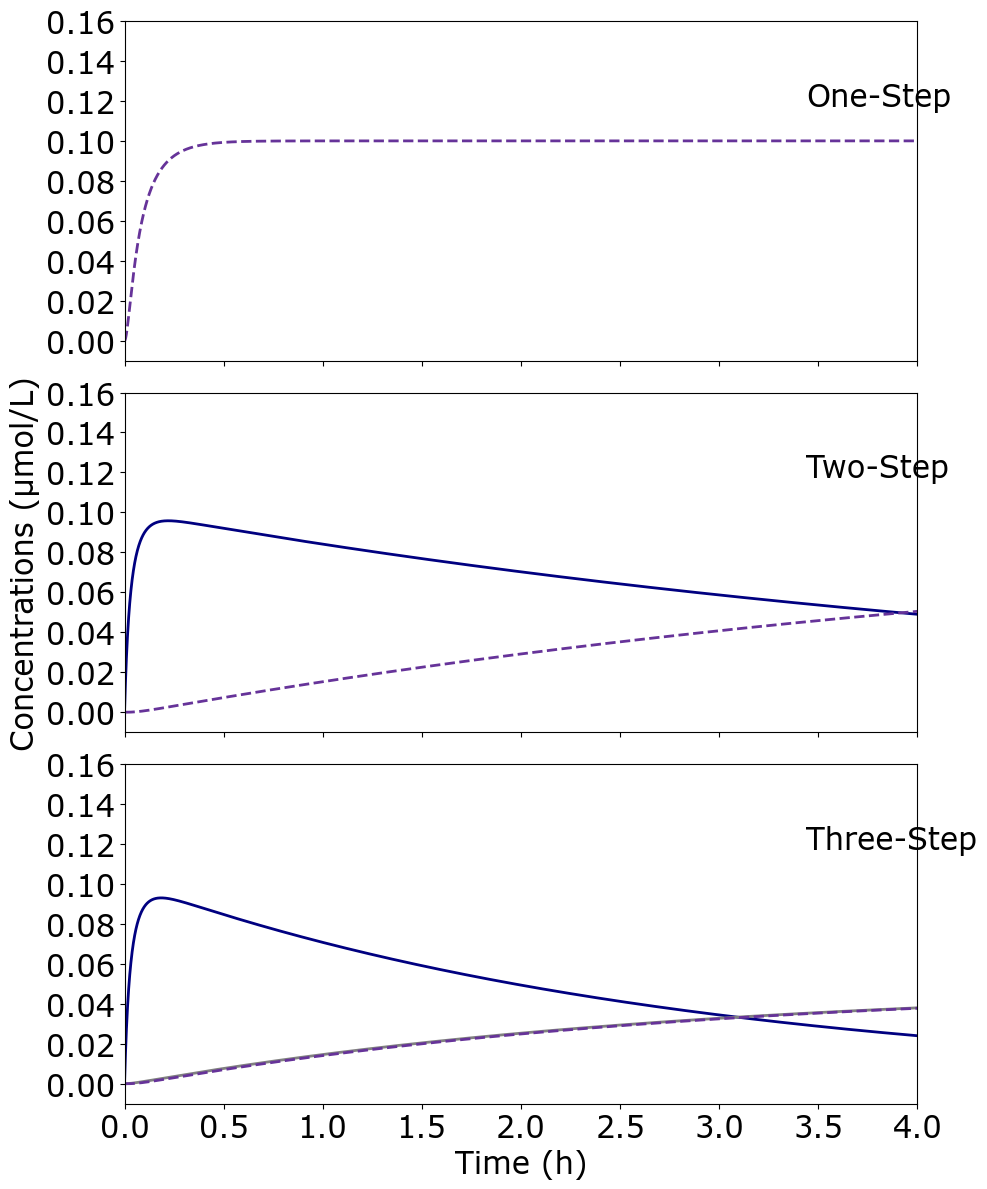

In [8]:
fig = plt.figure(figsize=(10, 12))  # Width set to match letter-size paper width (inches)
gs = GridSpec(3, 1, figure=fig, height_ratios=[1,1, 1])  # Equal heights for both subplots

for key, ax_num in zip(tmse_conditions.keys(), range(3)):
    mech_tmse = tmse_conditions[key][0]
    tmse_mechanisms = {mech_tmse.mechanism_type:mech_tmse}

    # Make Mixture and Compile
    M_DNAseesaw_AND = Mixture("SeeSaw_AND",
                              components=[step_tmse],
                              parameters=parameters_AND,
                              mechanisms=tmse_mechanisms)
    
    # Compile the CRN with Mixture.compile_crn
    CRN_DNAseesaw_AND = M_DNAseesaw_AND.compile_crn()

    # Simulate
    try:
        R = CRN_DNAseesaw_AND.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                               initial_condition_dict = initial_concentration_dict)
        time = R['time'] / 3600        
        ax=fig.add_subplot(gs[ax_num])

        #Plot
        plot_subplots(key, time, list_species, ax, ax_num, plot_dict)   

    except ModuleNotFoundError:
        print("Plotting Modules not installed.")

plt.savefig(f'{figs_dir}/SI_TMSEmechs_rev0.svg')
plt.tight_layout()

# Computing environment

In [9]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.4.0
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.3

